
# CONTROL ENGINEERING I
# TIME RESPONSE ANALYSIS USING PYTHON

## Practical Tutorial: Obtaining and Plotting the Time Response of a Control System

### Learning Objectives

By the end of this practical session, you should be able to:

1. Understand the meaning of time response in control systems.
2. Relate transfer functions to time-domain responses.
3. Understand standard test input signals.
4. Obtain time responses mathematically using inverse Laplace transforms.
5. Define transfer functions using Python.
6. Simulate impulse, step and ramp responses.
7. Extract numerical time-response data.
8. Plot and interpret the resulting response curves.
9. Understand important time-domain performance specifications.

### Software Requirements

- Python 3
- NumPy
- SciPy
- Matplotlib
- Jupyter Notebook


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from control import matlab as mt


## PYTHON ENVIRONMENT SETUP

Python provides powerful scientific computing libraries that can be used to simulate and analyse control systems.

We shall use the following libraries:

| Library | Purpose |
|---|---|
| NumPy | Numerical computations and arrays |
| SciPy | Transfer functions and system simulation |
| Matplotlib | Plotting and visualization |
| Pandas | Organizing and exporting response data |

Install the required packages using the following terminal command:

```bash
python3 -m pip install numpy scipy matplotlib pandas control
```

We can now import the libraries into our notebook.



## 1. INTRODUCTION TO TIME RESPONSE

Time response refers to the behaviour of a control system's output as a function of time when a particular input signal is applied.

In control engineering, we are interested in understanding how a system responds immediately after an input is introduced and how its output evolves with time.

For example:

- How quickly does a motor reach its desired speed?
- How long does a temperature control system take to reach its set temperature?
- Does the output oscillate before reaching its final value?
- Does the system eventually settle?
- Does the system become unstable?

These questions are investigated through time-response analysis.

### Mathematical Representation

For a linear time-invariant system, the transfer function is:

$$
G(s)=\frac{Y(s)}{R(s)}
$$

Therefore:

$$
Y(s)=G(s)R(s)
$$

The time-domain output is obtained using the inverse Laplace transform:

$$
\boxed{y(t)=\mathcal{L}^{-1}\{G(s)R(s)\}}
$$

Where:

- $G(s)$ is the system transfer function.
- $R(s)$ is the input in the Laplace domain.
- $Y(s)$ is the output in the Laplace domain.
- $y(t)$ is the output in the time domain.



## 2. STANDARD TEST INPUT SIGNALS

Control systems are commonly investigated using standard test signals.

These signals allow engineers to evaluate and compare the performance of different systems.

### 2.1 Unit Impulse Input

The unit impulse signal is represented by:

$$
r(t)=\delta(t)
$$

Its Laplace transform is:

$$
R(s)=1
$$

An ideal impulse has zero duration and unit area.

### 2.2 Unit-Step Input

The unit-step signal is:

$$
r(t)=u(t)
$$

Its Laplace transform is:

$$
R(s)=\frac{1}{s}
$$

The input changes from zero to one at $t=0$.

### 2.3 Unit-Ramp Input

The unit-ramp signal is:

$$
r(t)=tu(t)
$$

Its Laplace transform is:

$$
R(s)=\frac{1}{s^2}
$$

The input increases linearly with time.

### 2.4 Unit-Parabolic Input

The unit-parabolic signal is:

$$
r(t)=\frac{t^2}{2}u(t)
$$

Its Laplace transform is:

$$
R(s)=\frac{1}{s^3}
$$

### Summary

| Input | Time Domain | Laplace Domain |
|---|---|---|
| Impulse | $\delta(t)$ | $1$ |
| Step | $u(t)$ | $1/s$ |
| Ramp | $tu(t)$ | $1/s^2$ |
| Parabolic | $t^2u(t)/2$ | $1/s^3$ |



## 3. MATHEMATICAL DERIVATION OF TIME RESPONSE

Consider a first-order system with the transfer function:

$$
G(s)=\frac{5}{s+2}
$$

Determine its response to a unit-step input.

### Step 1: Identify the input

For a unit-step input:

$$
R(s)=\frac{1}{s}
$$

### Step 2: Calculate the output in the Laplace domain

We know:

$$
Y(s)=G(s)R(s)
$$

Substituting:

$$
Y(s)=\frac{5}{s+2}\times\frac{1}{s}
$$

Therefore:

$$
Y(s)=\frac{5}{s(s+2)}
$$

### Step 3: Apply partial fraction expansion

Assume:

$$
\frac{5}{s(s+2)}
=
\frac{A}{s}+\frac{B}{s+2}
$$

Multiplying through:

$$
5=A(s+2)+Bs
$$

Expanding:

$$
5=As+2A+Bs
$$

Comparing coefficients:

$$
A+B=0
$$

$$
2A=5
$$

Hence:

$$
A=2.5,\qquad B=-2.5
$$

Therefore:

$$
Y(s)=\frac{2.5}{s}-\frac{2.5}{s+2}
$$

### Step 4: Apply inverse Laplace transform

Using:

$$
\mathcal{L}^{-1}\left\{\frac{1}{s}\right\}=1
$$

and:

$$
\mathcal{L}^{-1}\left\{\frac{1}{s+a}\right\}=e^{-at}
$$

We obtain:

$$
\boxed{y(t)=2.5(1-e^{-2t})}
$$

This is the theoretical unit-step response of the system.

### Step 5: Determine the steady-state value

$$
y_{ss}=\lim_{t\to\infty}y(t)
$$

$$
\boxed{y_{ss}=2.5}
$$


In [4]:
num=[5]
den=[1,2]
sys=mt.tf(num,den)
sys

TransferFunction(
array([5]),
array([1, 2]),
outputs=1, inputs=1)

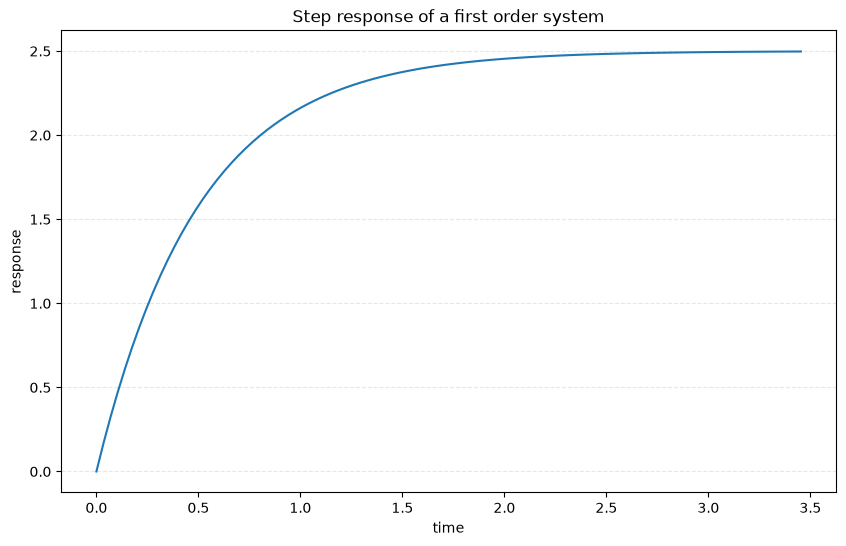

In [8]:
[y,t]=mt.step(sys)
plt.figure(figsize=(10,6))
plt.plot(t,y)
plt.title("Step response of a first order system")
plt.xlabel("time")
plt.ylabel("response")
plt.grid(True,alpha=0.3,linestyle='--',axis='y')
plt.show()

In [9]:
mt.stepinfo(sys)

{'RiseTime': 1.0815172406487183,
 'SettlingTime': 1.9885962166766757,
 'SettlingMin': 2.25,
 'SettlingMax': 2.5,
 'Overshoot': 0.0,
 'Undershoot': 0.0,
 'Peak': 2.4974999999999996,
 'PeakTime': 3.4538776394910684,
 'SteadyStateValue': 2.5}

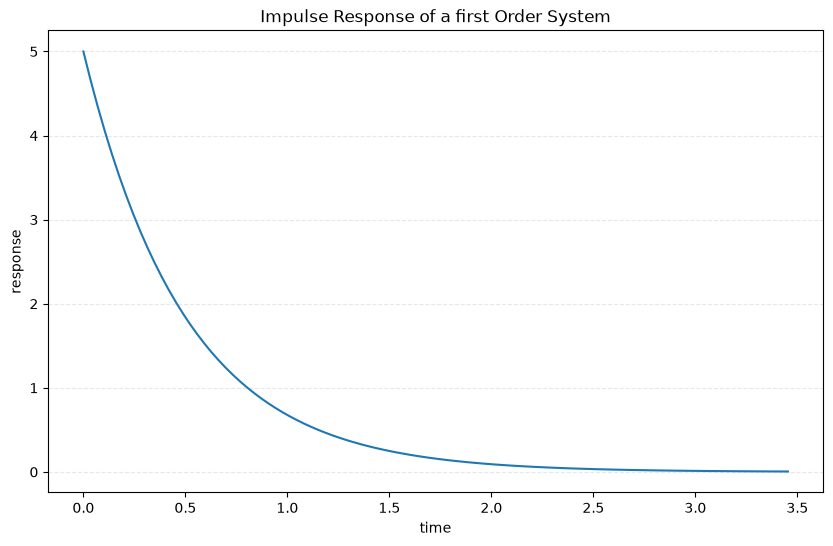

In [12]:
[y,t]=mt.impulse(sys)
plot_response(y,t,title="Impulse Response of a first Order System")

In [10]:
def plot_response(y,t,title=""):
    plt.figure(figsize=(10,6))
    plt.plot(t,y)
    plt.title(title)
    plt.xlabel("time")
    plt.ylabel("response")
    plt.grid(True,alpha=0.3,linestyle='--',axis='y')
    plt.show()


# SECOND-ORDER SYSTEMS: STEP AND IMPULSE RESPONSE

### Question 1

Given the transfer function:

$$
G(s)=\frac{25}{s^2+4s+25}
$$

Determine the unit-step response and unit-impulse response using inverse Laplace transforms. Plot both responses using Python.



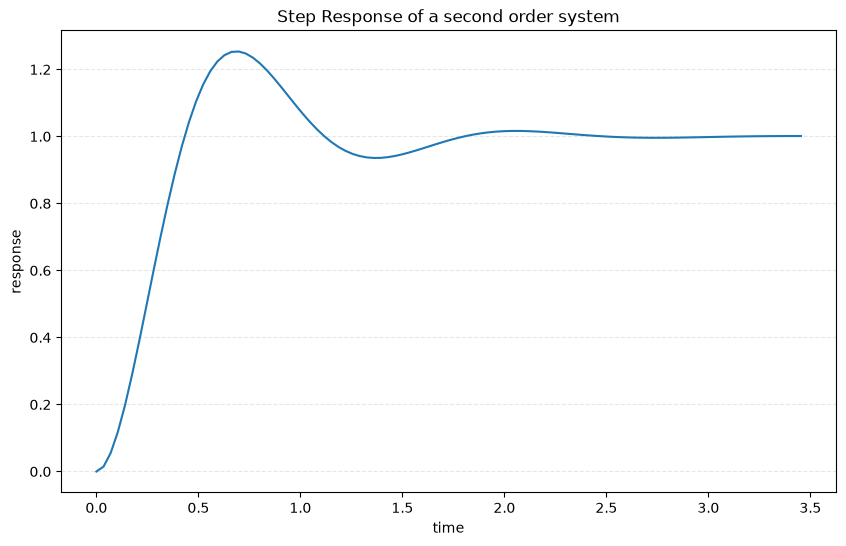

In [14]:
num=[25]
den=[1,4,25]
sys=mt.tf(num,den)
[y,t]=mt.step(sys)
plot_response(y,t,"Step Response of a second order system")

In [15]:
mt.stepinfo(sys)

{'RiseTime': 0.3139888763173698,
 'SettlingTime': 1.709494993283458,
 'SettlingMin': 0.9356617613694419,
 'SettlingMax': 1.253362108979423,
 'Overshoot': 25.33621089794229,
 'Undershoot': 0.0,
 'Peak': 1.253362108979423,
 'PeakTime': 0.697753058483044,
 'SteadyStateValue': 1.0}

### Question 2

Given the transfer function:

$$
G(s)=\frac{16}{s^2+8s+16}
$$

Determine the unit-step response and unit-impulse response using inverse Laplace transforms. Plot both responses using Python.


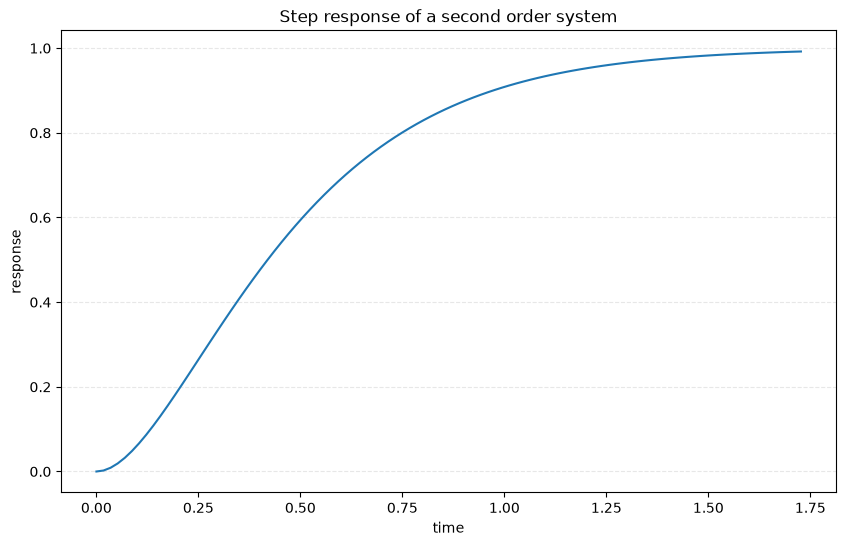

In [19]:
num=[16]
den=[1,8,16]
sys=mt.tf(num,den)
[y,t]=mt.step(sys)
plot_response(y,t,"Step response of a second order system")


### Question 3

Given the transfer function:

$$
G(s)=\frac{9}{s^2+8s+9}
$$

Determine the unit-step response and unit-impulse response using inverse Laplace transforms. Plot both responses using Python.



### Question 4

Given the transfer function:

$$
G(s)=\frac{36}{s^2+36}
$$

Determine the unit-step response and unit-impulse response using inverse Laplace transforms. Plot both responses using Python.
